# Data Aggregation & Cleaning

Goals:
- Aggregate PortWatch data to weekly data (Saturday to Friday, to match ACLED Data)
- Convert missing ACLED data to `NaN`
- Merge PortWatch and ACLED datasets for analysis

## Read in Data
Read in Data generated in `01_data_collection.ipynb`

In [2]:
import os.path

import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib
import os

In [3]:
DATA_DIR_RAW = Path("data/raw")
DATA_DIR_PROCESSED = Path("data/processed")

acled = pd.read_parquet(Path.joinpath(DATA_DIR_PROCESSED, "acled_scope.parquet"))
portwatch = pd.read_csv(Path.joinpath(DATA_DIR_RAW, "portwatch_chokepoints.csv"))

print(f"ACLED data shape: {acled.shape}")
print(f"Portwatch data shape: {portwatch.shape}")

ACLED data shape: (8008, 14)
Portwatch data shape: (5492, 21)


## Aggregate PortWatch
Portwatch data is reported and published on a daily basis, while ACLED data is only published weekly. In order to merge datasets, we aggregate Portwatch into weekly data, where Saturday is the first day of the week.
- First, the `date` column is converted from `str` datatype to `datetime` datatype.
- Next, the week number is found for each day. If it is a Saturday or Sunday, it will be added to the next week.
    - Pandas includes a handy function `dt.to_period` which lets us start on a saturday


In [4]:
## convert to datetime format
portwatch['date'] = pd.to_datetime(portwatch['date'], format='ISO8601') #convert to pd.datetime format
portwatch['week_start'] = portwatch['date'].dt.to_period('W-FRI').dt.start_time #weekly period that goes to friday.

#drop date, day, objectid col, as these not needed anymore and interfere with the groupby function
portwatch = portwatch.drop(['date', 'month', 'year', 'day', 'ObjectId'], axis = "columns")

Finally, we group the dataset by its week and chokepoint. We re-add the month and year column, but this time from the `week_start` column (instead of the original `date`), such that we can avoid issues where a single week spans over the end of a month or over the end of the year.

In [5]:
#groupby
portwatch['year'] = portwatch['week_start'].dt.year
portwatch['month'] = portwatch['week_start'].dt.month

portwatch_weekly = (
    portwatch
    .groupby(['week_start', 'portid', 'portname', 'year', 'month'], as_index=False)
    .sum()
)

Lastly, the ACLED dataset starts on the week of 2023-01-07, so we remove the first partial week from the `portwatch_weekly` dataset.

In [6]:
portwatch_weekly = portwatch_weekly[portwatch_weekly['week_start'] >= '2023-01-07'].reset_index(drop = True)
portwatch_weekly

,week_start,portid,portname,year,month,n_container,n_dry_bulk,n_general_cargo,n_roro,n_tanker,n_cargo,n_total,capacity_container,capacity_dry_bulk,capacity_general_cargo,capacity_roro,capacity_tanker,capacity_cargo,capacity
0,2023-01-07,chokepoint1,Suez Canal,2023,1,110,134,53,20,180,317,497,5278362,7675700,208821,71425,8783294,13234320,22017616
1,2023-01-07,chokepoint4,Bab el-Mandeb Strait,2023,1,110,143,35,24,155,312,467,5721333,7572575,176131,42754,7791736,13512805,21304545
2,2023-01-07,chokepoint6,Strait of Hormuz,2023,1,84,88,23,8,296,203,499,2420164,2567562,100026,18722,14272826,5106482,19379313
3,2023-01-07,chokepoint7,Cape of Good Hope,2023,1,49,181,14,5,68,249,317,1889132,12009885,207375,14000,5520769,14120399,19641169
4,2023-01-14,chokepoint1,Suez Canal,2023,1,120,130,46,19,175,315,490,6301202,6831129,242091,57390,9603387,13431822,23035210
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
779,2026-09-26,chokepoint7,Cape of Good Hope,2026,9,98,307,28,29,143,462,605,5669616,23616812,257048,142941,9394675,29686427,39081104
780,2026-10-03,chokepoint1,Suez Canal,2026,10,33,19,8,2,30,62,92,1281460,787837,52957,6160,1304674,2128416,3433091
781,2026-10-03,chokepoint4,Bab el-Mandeb Strait,2026,10,14,20,9,2,19,45,64,283170,878174,95260,0,1025691,1256607,2282298
782,2026-10-03,chokepoint6,Strait of Hormuz,2026,10,1,3,2,0,0,6,6,12829,137997,14371,0,0,165199,165199


## Filtering ACLED Data

To eliminate non-maritime ground combat noise (e.g. territorial shifts), records will be filtered specifically for the following types:
- event types: (already filtered)
    - '_Explosions/Remote violence_',
    - '_Battles_',
    - '_Strategic developments_'
- Subevent types:
    - ‘_Air/drone strike_’,
    - _Shelling/artillery/missile attack_’,
     - ‘_Disrupted weapons use_’ (capturing naval missile interceptions).

In [7]:
sub_events = ['Air/drone strike', 'Shelling/artillery/missile attack', 'Disrupted weapons use']
acled = acled[acled["SUB_EVENT_TYPE"].isin(sub_events)]
acled['SUB_EVENT_TYPE'].value_counts()

SUB_EVENT_TYPE
Air/drone strike                     1105
Shelling/artillery/missile attack     827
Disrupted weapons use                 689
Name: count, dtype: int64

In [8]:
## nan counts
acled.isnull().sum()

WEEK                     0
REGION                   0
COUNTRY                  0
ADMIN1                   0
EVENT_TYPE               0
SUB_EVENT_TYPE           0
EVENTS                   0
FATALITIES               0
POPULATION_EXPOSURE    896
DISORDER_TYPE            0
ID                       0
CENTROID_LATITUDE        0
CENTROID_LONGITUDE       0
maritime_sub_event       0
dtype: int64

The column `POPULATION_EXPOSURE` has 896 fields which are listed as NaN.

In [9]:
acled[acled['POPULATION_EXPOSURE'].isnull()][['COUNTRY' ,'ADMIN1']].value_counts()

COUNTRY               ADMIN1                    
Indian Ocean          North Indian Ocean            250
Yemen                 Al Hudaydah                    52
                      Abyan                          36
                      Shabwah                        35
                      Lahij                          33
                      Taizz                          33
                      Aden                           27
Iran                  Hormozgan                      25
Oman                  Musandam                       25
Yemen                 Marib                          24
                      Hadramawt                      22
Iran                  Sistan and Baluchestan         21
                      Tehran                         20
Yemen                 Hajjah                         19
                      Al Jawf                        17
                      Al Mahrah                      17
                      Sadah                          16

When selecting NaN values per country and Administrative region, it becomes evident that the vast majority of NaN values are located in the Indian ocean. As such, it becomes a valid assumption that events with NaN data fields occured in a remote enough region that there was little to no public population exposed to the event. As a result, all NaN fields are replaced with 0.

In [10]:
acled['POPULATION_EXPOSURE'] = acled['POPULATION_EXPOSURE'].fillna(0)
print(f"Number of NaN values in POPULATION_EXPOSURE: {acled['POPULATION_EXPOSURE'].isnull().sum()}")

Number of NaN values in POPULATION_EXPOSURE: 0


# Combining Datasets (update image)
The ACELD and Portwatch datasets will now get combined for use in the answering each specific question with applicable data.

Resulting datasets:
- Dataset 1 for research question 1
- Dataset 2 for research question 2
- Dataset 3 for research question 3
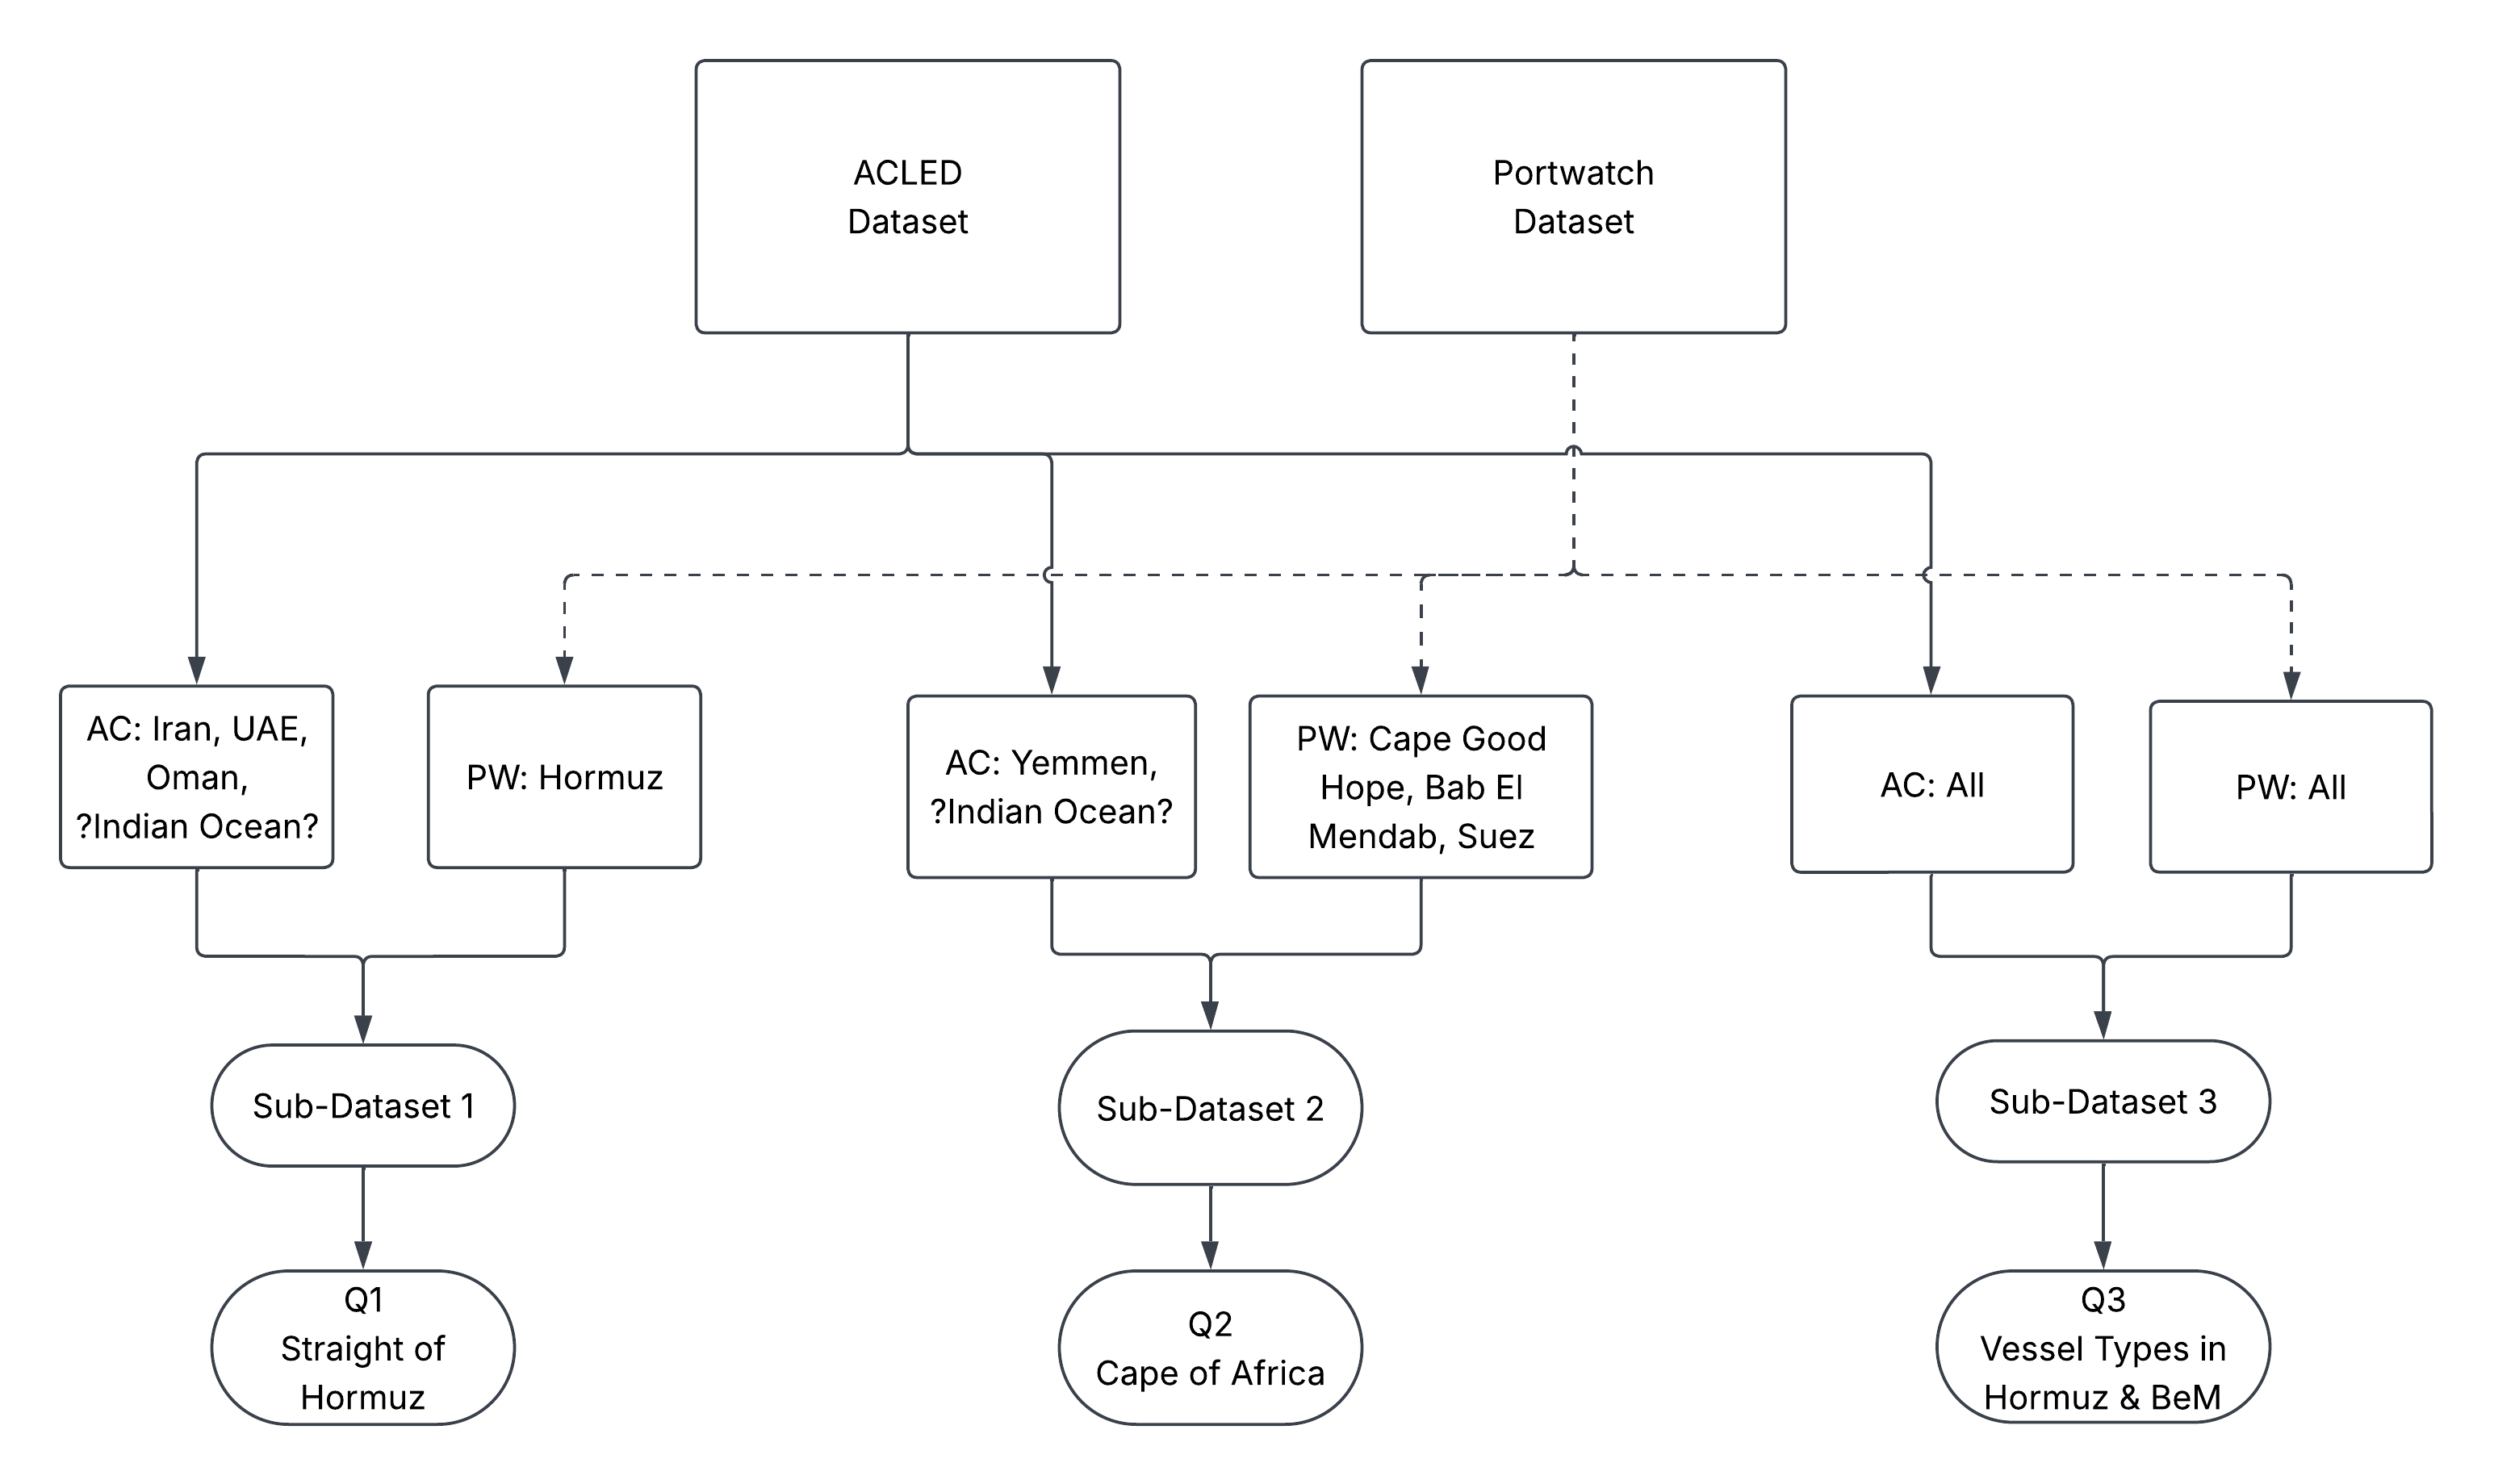

## Dataset 1
Combines the following:

- From ACLED, data with the `country` field, aggregated on a weekly basis:
    - Iran
    - UAE
    - Oman
    - Indian Ocean

- From Portwatch weekly aggregated data,`portname` field:
    - Straight of Hormuz (`portid == chokepoint6`)

In [11]:
portwatch_ds_1 = portwatch_weekly[portwatch_weekly['portid'] == 'chokepoint6']

In [12]:
# aggregate by country in ACLED
acled_ds_1 = acled[acled['COUNTRY'] != 'Yemen'] # yemen is the only country not included in DS1
acled_ds_1.groupby(
    by = ['WEEK', 'COUNTRY'],
    as_index=False
).sum()
acled_ds_1

,WEEK,REGION,COUNTRY,ADMIN1,EVENT_TYPE,SUB_EVENT_TYPE,EVENTS,FATALITIES,POPULATION_EXPOSURE,DISORDER_TYPE,ID,CENTROID_LATITUDE,CENTROID_LONGITUDE,maritime_sub_event
16,2023-02-04,International Waters,Indian Ocean,North Indian Ocean,Explosions/Remote violence,Air/drone strike,1,0,0.0,Political violence,4199,13.7278,70.4734,True
17,2023-11-18,International Waters,Indian Ocean,North Indian Ocean,Explosions/Remote violence,Air/drone strike,1,0,0.0,Political violence,4199,13.7278,70.4734,True
18,2023-11-25,International Waters,Indian Ocean,North Indian Ocean,Explosions/Remote violence,Air/drone strike,1,0,0.0,Political violence,4199,13.7278,70.4734,True
19,2023-12-09,International Waters,Indian Ocean,North Indian Ocean,Explosions/Remote violence,Air/drone strike,2,0,0.0,Political violence,4199,13.7278,70.4734,True
20,2023-12-16,International Waters,Indian Ocean,North Indian Ocean,Explosions/Remote violence,Air/drone strike,2,0,0.0,Political violence,4199,13.7278,70.4734,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1847,2026-04-04,Middle East,United Arab Emirates,Dubai,Strategic developments,Disrupted weapons use,1,0,0.0,Strategic developments,3476,24.9904,55.3711,True
1848,2026-08-29,Middle East,United Arab Emirates,Dubai,Strategic developments,Disrupted weapons use,2,0,0.0,Strategic developments,3476,24.9904,55.3711,True
1850,2026-02-28,Middle East,United Arab Emirates,Ras Al Khaymah,Explosions/Remote violence,Air/drone strike,2,0,56031.0,Political violence,3477,25.6980,55.9686,True
1851,2026-02-28,Middle East,United Arab Emirates,Ras Al Khaymah,Strategic developments,Disrupted weapons use,1,0,0.0,Strategic developments,3477,25.6980,55.9686,True


In [13]:
# save dataset to parquet
dir_ds1 = 'data/processed/dataset_1'
if not os.path.isdir(dir_ds1):
    os.makedirs(dir_ds1)

portwatch_ds_1.to_parquet(f'{dir_ds1}/portwatch_ds_1.parquet')
acled_ds_1.to_parquet(f'{dir_ds1}/acled_ds_1.parquet')

## Dataset 2
Combines the following:
- From ACLED, data with the `country` field, aggregated on a weekly basis:
    - Yemen

- From Portwatch weekly aggregated data:
    - Suez Canal (`portid == chokepoint1`)
    - Cape of Good Hope (`portid == chokepoint7`)
    - Bab El- Mendeb Straight(`portid == chokepoint4`)

In [14]:
portwatch_ds_2 = portwatch_weekly[portwatch_weekly['portid'] != 'chokepoint6'] #includes all but straight of hormuz

In [15]:
acled_ds_2 = acled[acled['COUNTRY'] == 'Yemen']

## remove all categorical / non-numerical events as they get mixed when running the groupby
acled_ds_2 = acled_ds_2.drop(['REGION',
                              'ADMIN1',
                              'EVENT_TYPE',
                              'SUB_EVENT_TYPE',
                              'DISORDER_TYPE',
                              'ID',
                              'CENTROID_LATITUDE',
                              'CENTROID_LONGITUDE'],
                             axis = "columns")
acled_ds_2.groupby(
    by = ['WEEK', 'COUNTRY'],
    as_index=False
).sum()

,WEEK,COUNTRY,EVENTS,FATALITIES,POPULATION_EXPOSURE,maritime_sub_event
0,2023-01-07,Yemen,27,4,169260.0,14
1,2023-01-14,Yemen,23,18,73982.0,8
2,2023-01-21,Yemen,32,15,268295.0,13
3,2023-01-28,Yemen,28,6,220255.0,10
4,2023-02-04,Yemen,27,4,129667.0,10
...,...,...,...,...,...,...
189,2026-08-29,Yemen,100,80,1562933.0,26
190,2026-09-05,Yemen,204,241,2702845.0,29
191,2026-09-12,Yemen,191,195,2496387.0,28
192,2026-09-19,Yemen,170,158,2892899.0,28


In [16]:
# save dataset to parquet
dir_ds2 = 'data/processed/dataset_2'
if not os.path.isdir(dir_ds2):
    os.makedirs(dir_ds2)

portwatch_ds_1.to_parquet(f'{dir_ds2}/portwatch_ds_2.parquet')
acled_ds_1.to_parquet(f'{dir_ds2}/acled_ds_2.parquet')

## Dataset 3
Combines the following:
- From ACLED, data with the `country` field, aggregated on a weekly basis:
    - all

- From Portwatch weekly aggregated data:
    - all ports

In [17]:
portwatch_ds_3 = portwatch_weekly

In [18]:
acled_ds_3 = acled

## non-numerical items removed prior to grouping.
acled_ds_3 = acled_ds_3.drop(['REGION',
                              'ADMIN1',
                              'EVENT_TYPE',
                              'SUB_EVENT_TYPE',
                              'DISORDER_TYPE',
                              'ID',
                              'CENTROID_LATITUDE',
                              'CENTROID_LONGITUDE'],
                             axis = "columns")

acled_ds_3.groupby(by = ['WEEK', 'COUNTRY'],
                   as_index=False,
                   ).sum()

,WEEK,COUNTRY,EVENTS,FATALITIES,POPULATION_EXPOSURE,maritime_sub_event
0,2023-01-07,Yemen,27,4,169260.0,14
1,2023-01-14,Indian Ocean,1,0,0.0,1
2,2023-01-14,Yemen,23,18,73982.0,8
3,2023-01-21,Yemen,32,15,268295.0,13
4,2023-01-28,Yemen,28,6,220255.0,10
...,...,...,...,...,...,...
412,2026-09-19,Oman,4,1,0.0,2
413,2026-09-19,Yemen,170,158,2892899.0,28
414,2026-09-26,Iran,4,0,0.0,4
415,2026-09-26,Oman,7,0,0.0,2


In [19]:
# save dataset to parquet
dir_ds3 = 'data/processed/dataset_3'
if not os.path.isdir(dir_ds3):
    os.makedirs(dir_ds3)

portwatch_ds_1.to_parquet(f'{dir_ds3}/portwatch_ds_3.parquet')
acled_ds_1.to_parquet(f'{dir_ds3}/acled_ds_3.parquet')